In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kmmohammadsinan/procurement-fraud-detection/train.csv
/kaggle/input/datasets/kmmohammadsinan/procurement-fraud-detection/test.csv


In [16]:
import sqlite3, shutil
import pandas as pd
from pathlib import Path

SRC  = Path("/kaggle/input/datasets/kmmohammadsinan/procurement-fraud-detection")
ROOT = Path("/kaggle/working/procurement-fraud-detection")

for d in ["data/raw", "data/processed", "sql", "notebooks", "reports", "docs"]:
    (ROOT / d).mkdir(parents=True, exist_ok=True)

for f in ["train.csv", "test.csv"]:
    shutil.copy(SRC / f, ROOT / "data/raw" / f)

train = pd.read_csv(ROOT / "data/raw/train.csv")
test  = pd.read_csv(ROOT / "data/raw/test.csv")

con = sqlite3.connect(ROOT / "data/processed/tenders.db")
train.to_sql("train", con, if_exists="replace", index=False)
test.to_sql("test",  con, if_exists="replace", index=False)
print(len(train), len(test))

5092 2546


In [17]:
audit_sql = """
-- Query 1: row count and fraud rate
SELECT COUNT(*) AS rows_total,
       SUM(y) AS fraud_cases,
       ROUND(100.0 * SUM(y) / COUNT(*), 2) AS fraud_pct
FROM train;

-- Query 2: missing values and duplicate ids
SELECT SUM(obs_count IS NULL) AS null_obs,
       SUM(std IS NULL)       AS null_std,
       SUM(median IS NULL)    AS null_median,
       SUM(mean IS NULL)      AS null_mean,
       SUM(skew IS NULL)      AS null_skew,
       COUNT(*) - COUNT(DISTINCT id) AS duplicate_ids
FROM train;

-- Query 3: feature ranges by fraud flag
SELECT y,
       COUNT(*)            AS n,
       MIN(obs_count)      AS min_obs,
       MAX(obs_count)      AS max_obs,
       ROUND(AVG(std), 2)  AS avg_std,
       ROUND(AVG(skew), 2) AS avg_skew
FROM train
GROUP BY y;
"""
(ROOT / "sql/02_audit.sql").write_text(audit_sql)

queries = [q.strip() for q in (ROOT / "sql/02_audit.sql").read_text().split(";") if "SELECT" in q]
for i, q in enumerate(queries, 1):
    out = pd.read_sql(q, con)
    out.to_csv(ROOT / f"reports/02_audit_query{i}.csv", index=False)
    print(f"Query {i}")
    print(out.to_string(index=False), "\n")

Query 1
 rows_total  fraud_cases  fraud_pct
       5092           99       1.94 

Query 2
 null_obs  null_std  null_median  null_mean  null_skew  duplicate_ids
        0         0            0          0          0              0 

Query 3
 y    n  min_obs  max_obs  avg_std  avg_skew
 0 4993      101    26021     7.63      4.67
 1   99      174    26765    21.23      8.72 



**SQL feature analysis**

In [18]:
features = ["obs_count", "std", "skew", "median", "mean"]

template = """
-- Fraud rate by quintile of {col}
WITH q AS (
  SELECT y, {col} AS v, NTILE(5) OVER (ORDER BY {col}) AS quintile
  FROM train
)
SELECT '{col}'        AS feature,
       quintile,
       COUNT(*)       AS hospitals,
       ROUND(MIN(v), 2) AS min_value,
       ROUND(MAX(v), 2) AS max_value,
       SUM(y)         AS fraud_cases,
       ROUND(100.0 * SUM(y) / COUNT(*), 2) AS fraud_pct
FROM q
GROUP BY quintile
ORDER BY quintile;
"""

sql_text = "\n".join(template.format(col=c) for c in features)
(ROOT / "sql/03_feature_analysis.sql").write_text(sql_text)

queries = [q.strip() for q in sql_text.split(";") if "SELECT" in q]
frames = []
for q in queries:
    out = pd.read_sql(q, con)
    frames.append(out)
    print(out.to_string(index=False), "\n")

pd.concat(frames).to_csv(ROOT / "reports/03_quintile_fraud_rates.csv", index=False)

  feature  quintile  hospitals  min_value  max_value  fraud_cases  fraud_pct
obs_count         1       1019      101.0      392.0            3       0.29
obs_count         2       1019      392.0      880.0            4       0.39
obs_count         3       1018      881.0     1599.0            7       0.69
obs_count         4       1018     1600.0     2981.0           17       1.67
obs_count         5       1018     2982.0    26765.0           68       6.68 

feature  quintile  hospitals  min_value  max_value  fraud_cases  fraud_pct
    std         1       1019       0.32       3.45            0       0.00
    std         2       1019       3.45       4.84            0       0.00
    std         3       1018       4.84       6.71            1       0.10
    std         4       1018       6.72       9.88           16       1.57
    std         5       1018       9.89     717.32           82       8.06 

feature  quintile  hospitals  min_value  max_value  fraud_cases  fraud_pct
   skew  

In [19]:
corr = train.corr()["y"].drop(["y", "id"]).round(3).sort_values(ascending=False)
print(corr, "\n")
corr.to_csv(ROOT / "reports/03_correlation_with_fraud.csv", header=["corr_with_y"])

share_sql = """
-- Share of all fraud cases found in the top 20% of hospitals for each feature
WITH r AS (
  SELECT y,
         NTILE(5) OVER (ORDER BY std)       AS q_std,
         NTILE(5) OVER (ORDER BY obs_count) AS q_obs,
         NTILE(5) OVER (ORDER BY skew)      AS q_skew
  FROM train
)
SELECT ROUND(100.0 * SUM(CASE WHEN q_std  = 5 THEN y END) / SUM(y), 1) AS pct_fraud_in_top_std,
       ROUND(100.0 * SUM(CASE WHEN q_obs  = 5 THEN y END) / SUM(y), 1) AS pct_fraud_in_top_obs,
       ROUND(100.0 * SUM(CASE WHEN q_skew = 5 THEN y END) / SUM(y), 1) AS pct_fraud_in_top_skew
FROM r;
"""
(ROOT / "sql/03b_top_quintile_share.sql").write_text(share_sql)
share = pd.read_sql(share_sql, con)
print(share.to_string(index=False))
share.to_csv(ROOT / "reports/03b_top_quintile_share.csv", index=False)

obs_count    0.253
std          0.137
skew         0.126
mean         0.071
median       0.039
Name: y, dtype: float64 

 pct_fraud_in_top_std  pct_fraud_in_top_obs  pct_fraud_in_top_skew
                 82.8                  68.7                   50.5


**Imports, Filter and SMOTE**

In [20]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score, recall_score, roc_curve, auc, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

corr = train.corr()["y"].abs()
selected = [c for c in corr[corr >= 0.1].index if c != "y"]
print("Selected features:", selected)

X, y = train[selected], train["y"]
X_res, y_res = SMOTE(random_state=42).fit_resample(X, y)
print("After SMOTE:", X_res.shape, "fraud share:", y_res.mean())

Selected features: ['obs_count', 'std', 'skew']
After SMOTE: (9986, 3) fraud share: 0.5


**The eight models, 5-fold CV**

In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "SVM": SVC(probability=True),
    "KNN": KNeighborsClassifier(),
    "MLP": MLPClassifier(max_iter=500),
    "XGBoost": XGBClassifier(eval_metric="logloss"),
    "LightGBM": LGBMClassifier(verbose=-1),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    f1s, recs, aucs = [], [], []
    for tr_i, te_i in skf.split(X_res, y_res):
        model.fit(X_res.iloc[tr_i], y_res.iloc[tr_i])
        pred = model.predict(X_res.iloc[te_i])
        prob = model.predict_proba(X_res.iloc[te_i])[:, 1]
        f1s.append(f1_score(y_res.iloc[te_i], pred))
        recs.append(recall_score(y_res.iloc[te_i], pred))
        aucs.append(auc(*roc_curve(y_res.iloc[te_i], prob)[:2]))
    rows.append({"Model": name, "AUC": np.mean(aucs), "Recall": np.mean(recs), "F1": np.mean(f1s)})

thesis_cv = pd.DataFrame(rows).sort_values("AUC", ascending=False).round(4)
thesis_cv.to_csv(ROOT / "reports/04_thesis_replication_cv.csv", index=False)
thesis_cv

,Model,AUC,Recall,F1
1,Random Forest,0.9892,0.9826,0.9514
6,XGBoost,0.9853,0.9836,0.9548
7,LightGBM,0.9845,0.9860,0.9524
2,Gradient Boosting,0.9696,0.9692,0.9217
4,KNN,0.9290,0.9061,0.8698
0,Logistic Regression,0.9127,0.7597,0.8027
5,MLP,0.8613,0.8398,0.7337
3,SVM,0.8052,0.7326,0.7490


**The confusion matrix**

[[925  74]
 [ 19 980]] | test rows: 1998 | fraud rows: 999


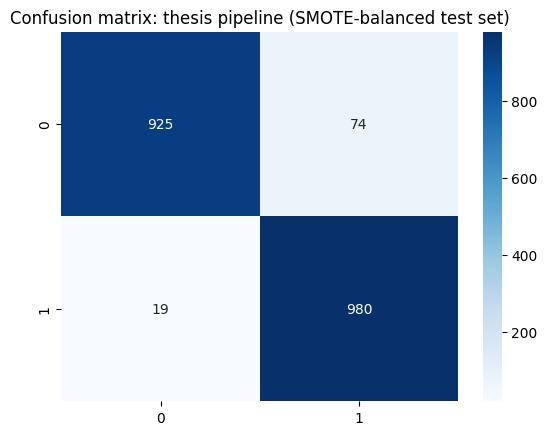

In [22]:
import matplotlib.pyplot as plt, seaborn as sns

X_tr, X_te, y_tr, y_te = train_test_split(X_res, y_res, test_size=0.2,
                                          random_state=42, stratify=y_res)
rf = RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42).fit(X_tr, y_tr)
cm = confusion_matrix(y_te, rf.predict(X_te))
print(cm, "| test rows:", len(y_te), "| fraud rows:", int(y_te.sum()))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion matrix: thesis pipeline (SMOTE-balanced test set)")
plt.savefig(ROOT / "reports/04_confusion_matrix_thesis.png", dpi=200, bbox_inches="tight")
plt.show()

**Imports and the evaluation function**

In [32]:
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline

def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "SVM": SVC(),
        "KNN": KNeighborsClassifier(),
        "MLP": MLPClassifier(max_iter=500, random_state=42),
        "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
        "LightGBM": LGBMClassifier(random_state=42, verbose=-1),
    }

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def honest_cv(cols):
    X, y = train[cols], train["y"]
    rows = []
    for name, model in make_models().items():
        pipe = Pipeline([("scale", StandardScaler()),
                         ("smote", SMOTE(random_state=42)),
                         ("model", model)])
        s = cross_validate(pipe, X, y, cv=skf, scoring=["roc_auc", "average_precision"])
        rows.append({"Model": name,
                     "AUC": s["test_roc_auc"].mean(), "AUC_sd": s["test_roc_auc"].std(),
                     "AvgPrecision": s["test_average_precision"].mean()})
    return pd.DataFrame(rows).sort_values("AUC", ascending=False).round(3)

In [33]:
three = honest_cv(["obs_count", "std", "skew"])
five  = honest_cv(["obs_count", "std", "median", "mean", "skew"])

three.to_csv(ROOT / "reports/05_leakage_free_3features.csv", index=False)
five.to_csv(ROOT / "reports/05_leakage_free_5features.csv", index=False)

print("3 features (thesis set)"); print(three.to_string(index=False)); print()
print("5 features");              print(five.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarnin

3 features (thesis set)
              Model   AUC  AUC_sd  AvgPrecision
           LightGBM 0.902   0.023         0.249
  Gradient Boosting 0.902   0.028         0.252
      Random Forest 0.895   0.023         0.182
            XGBoost 0.895   0.024         0.228
Logistic Regression 0.894   0.015         0.180
                MLP 0.892   0.019         0.213
                SVM 0.888   0.030         0.149
                KNN 0.783   0.044         0.085

5 features
              Model   AUC  AUC_sd  AvgPrecision
  Gradient Boosting 0.907   0.019         0.205
           LightGBM 0.903   0.016         0.254
Logistic Regression 0.898   0.012         0.259
                SVM 0.898   0.024         0.174
            XGBoost 0.896   0.022         0.225
      Random Forest 0.890   0.028         0.189
                MLP 0.889   0.018         0.193
                KNN 0.785   0.043         0.096


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [34]:
compare = (thesis_cv[["Model", "AUC"]].rename(columns={"AUC": "Thesis AUC (SMOTE before CV)"})
           .merge(three[["Model", "AUC"]].rename(columns={"AUC": "Leakage-free AUC (3 features)"}), on="Model")
           .merge(five[["Model", "AUC"]].rename(columns={"AUC": "Leakage-free AUC (5 features)"}), on="Model"))
compare.to_csv(ROOT / "reports/05_thesis_vs_leakage_free.csv", index=False)
compare

,Model,Thesis AUC (SMOTE before CV),Leakage-free AUC (3 features),Leakage-free AUC (5 features)
0,Random Forest,0.9892,0.895,0.890
1,XGBoost,0.9853,0.895,0.896
2,LightGBM,0.9845,0.902,0.903
3,Gradient Boosting,0.9696,0.902,0.907
4,KNN,0.9290,0.783,0.785
5,Logistic Regression,0.9127,0.894,0.898
6,MLP,0.8613,0.892,0.889
7,SVM,0.8052,0.888,0.898


**Risk bands and SHAP explanations**

In [35]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

cols5 = ["obs_count", "std", "median", "mean", "skew"]
X5, y = train[cols5], train["y"]

pipe = Pipeline([("scale", StandardScaler()),
                 ("smote", SMOTE(random_state=42)),
                 ("model", LogisticRegression(max_iter=2000))])

# every hospital is scored by a model that never saw it
train["score"] = cross_val_predict(pipe, X5, y, cv=skf, method="predict_proba")[:, 1]
print("Out-of-fold AUC:", round(roc_auc_score(y, train["score"]), 3))

q95, q80 = train["score"].quantile([0.95, 0.80])
train["band"] = np.where(train["score"] >= q95, "High",
                 np.where(train["score"] >= q80, "Medium", "Low"))
print("Cutoffs:", round(q95, 4), round(q80, 4))

Out-of-fold AUC: 0.897
Cutoffs: 0.8281 0.4292


In [36]:
train[["id", "y", "score", "band"]].to_sql("scores", con, if_exists="replace", index=False)

bands_sql = """
SELECT band,
       COUNT(*)                                   AS hospitals,
       SUM(y)                                     AS fraud_cases,
       ROUND(100.0 * SUM(y) / COUNT(*), 2)        AS fraud_pct,
       ROUND(100.0 * SUM(y) / (SELECT SUM(y) FROM scores), 1) AS pct_of_all_fraud
FROM scores
GROUP BY band
ORDER BY CASE band WHEN 'High' THEN 1 WHEN 'Medium' THEN 2 ELSE 3 END;
"""
(ROOT / "sql/06_risk_bands.sql").write_text(bands_sql)
bands = pd.read_sql(bands_sql, con)
bands.to_csv(ROOT / "reports/06_risk_bands.csv", index=False)
bands

,band,hospitals,fraud_cases,fraud_pct,pct_of_all_fraud
0,High,255,50,19.61,50.5
1,Medium,764,30,3.93,30.3
2,Low,4073,19,0.47,19.2


Background dataset has 9986 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=9986 when initializing the masker.


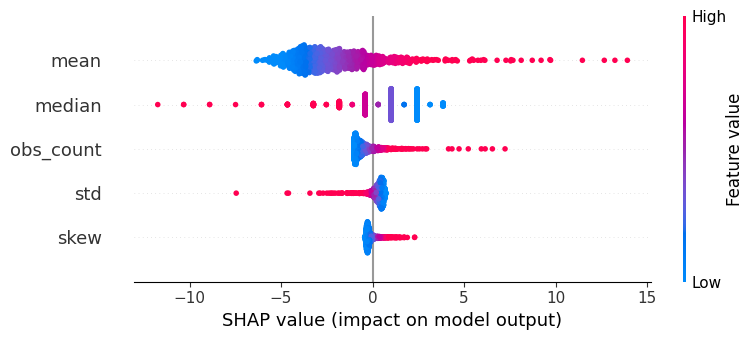

mean         2.719
median       1.639
obs_count    0.731
std          0.442
skew         0.296
dtype: float64


In [37]:
import shap, matplotlib.pyplot as plt

X_bal, y_bal = SMOTE(random_state=42).fit_resample(X5, y)
scaler = StandardScaler().fit(X_bal)
lr = LogisticRegression(max_iter=2000).fit(scaler.transform(X_bal), y_bal)

sample = X5.sample(1000, random_state=42)
explainer = shap.LinearExplainer(lr, scaler.transform(X_bal))
sv = explainer.shap_values(scaler.transform(sample))

shap.summary_plot(sv, sample, show=False)
plt.savefig(ROOT / "reports/06_shap_summary_logreg.png", dpi=200, bbox_inches="tight")
plt.show()

imp = pd.Series(np.abs(sv).mean(0), index=cols5).sort_values(ascending=False).round(3)
imp.to_csv(ROOT / "reports/06_shap_importance_logreg.csv", header=["mean_abs_shap"])
print(imp)

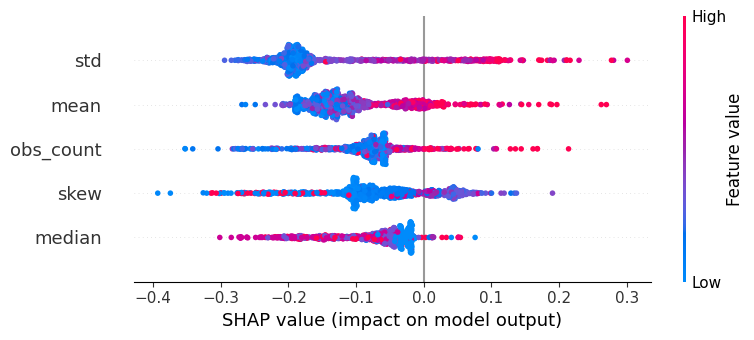

std          0.160
mean         0.111
obs_count    0.086
skew         0.086
median       0.076
dtype: float64


In [38]:
rf = RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42).fit(X_bal, y_bal)
sv_rf = shap.TreeExplainer(rf).shap_values(sample)
sv_rf = sv_rf[1] if isinstance(sv_rf, list) else (sv_rf[:, :, 1] if sv_rf.ndim == 3 else sv_rf)

shap.summary_plot(sv_rf, sample, show=False)
plt.savefig(ROOT / "reports/06_shap_summary_rf.png", dpi=200, bbox_inches="tight")
plt.show()
print(pd.Series(np.abs(sv_rf).mean(0), index=cols5).sort_values(ascending=False).round(3))

**Export the model and scores**

In [39]:
import json

# convert the standardised logistic model back to raw feature units
w_raw = lr.coef_[0] / scaler.scale_
b_raw = float(lr.intercept_[0] - np.sum(lr.coef_[0] * scaler.mean_ / scaler.scale_))

def raw_score(df):
    z = df[cols5].values @ w_raw + b_raw
    return 1 / (1 + np.exp(-z))

# sanity check: the exported formula must reproduce the sklearn model
chk = np.abs(raw_score(X5) - lr.predict_proba(scaler.transform(X5))[:, 1]).max()
print("Max difference vs sklearn model:", chk)

train["final_score"] = raw_score(train)
print("In-sample AUC of the final model (optimistic, for reference only):",
      round(roc_auc_score(y, train["final_score"]), 3))

Max difference vs sklearn model: 4.440892098500626e-16
In-sample AUC of the final model (optimistic, for reference only): 0.902


In [40]:
test["score"] = raw_score(test)
test["band"] = np.where(test["score"] >= q95, "High",
                np.where(test["score"] >= q80, "Medium", "Low"))
test[["id", "score", "band"]].to_csv(ROOT / "data/processed/test_scores.csv", index=False)
test[["id", "score", "band"]].to_sql("test_scores", con, if_exists="replace", index=False)

top_sql = """
SELECT t.id, t.obs_count, ROUND(t.std, 1) AS std, t.median,
       ROUND(t.mean, 1) AS mean, ROUND(t.skew, 1) AS skew,
       ROUND(s.score, 3) AS score, s.band
FROM test t JOIN test_scores s ON s.id = t.id
ORDER BY s.score DESC
LIMIT 25;
"""
(ROOT / "sql/07_top_risk_test.sql").write_text(top_sql)
top = pd.read_sql(top_sql, con)
top.to_csv(ROOT / "reports/07_top25_test_hospitals.csv", index=False)

print(test["band"].value_counts())
top.head(10)

band
Low       2032
Medium     374
High       140
Name: count, dtype: int64


,id,obs_count,std,median,mean,skew,score,band
0,6965,535,89.5,4.0,41.2,2.3,1.000,High
1,7586,124,25.0,1.0,15.5,1.5,1.000,High
2,5095,22968,54.8,9.0,19.0,26.2,1.000,High
3,5636,2882,26.7,4.0,16.3,3.0,1.000,High
4,5093,41305,552.6,8.0,39.6,32.1,0.999,High
5,5099,16247,23.8,7.0,15.4,3.7,0.999,High
6,5097,17803,66.6,8.0,16.8,28.1,0.999,High
7,5841,2203,26.1,5.0,16.8,2.6,0.999,High
8,5096,21161,111.0,8.0,17.6,33.3,0.999,High
9,5428,4015,37.1,5.0,16.3,5.3,0.999,High


In [41]:
feat_info = {c: {"mean": float(train[c].mean()),
                 "min": float(train[c].min()), "max": float(train[c].max())} for c in cols5}

payload = {
    "features": cols5,
    "weights": [float(w) for w in w_raw],
    "bias": b_raw,
    "cutoffs": {"high": float(q95), "medium": float(q80)},
    "feature_info": feat_info,
    "oof_auc": round(float(roc_auc_score(y, train["score"])), 3),
    "base_rate": round(float(y.mean()), 4),
    "bands": bands.to_dict("records"),
    "top_test": top.to_dict("records"),
    "thesis_vs_honest": compare.to_dict("records"),
    "shap_rf": {k: float(v) for k, v in
                pd.Series(np.abs(sv_rf).mean(0), index=cols5).round(3).items()},
}
(ROOT / "docs").mkdir(exist_ok=True)
(ROOT / "docs/data.json").write_text(json.dumps(payload, indent=2))
print(json.dumps(payload["cutoffs"]), payload["weights"])

{"high": 0.8281003342806418, "medium": 0.42918563322551856} [0.00031848188197058653, -0.06502437043981829, -1.4170772199570867, 1.0612330057337869, 0.08204939384132498]


In [42]:
con.close()
shutil.make_archive("/kaggle/working/procurement-fraud-detection", "zip", ROOT)

'/kaggle/working/procurement-fraud-detection.zip'